# 01 · EDA of Source 1: the coffee e-nose dataset

**What this notebook does.** It loads the 58 public e-nose measurements (Rodríguez et al., 2010), checks their format (rows, columns, missing values, class balance), plots the raw sensor curves, compares the classes and redoes the paper's PCA view. Every finding is copied into `docs/data_notes.md`.

**Background.** Each file is one measurement: 8 metal-oxide (MOX) gas sensors sampled once per second for 300 s. A MOX sensor's resistance *drops* when reducing gases (coffee volatiles) reach it, so the curves go down when the odour arrives.

In [1]:
import sys, os
from pathlib import Path
ROOT = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(ROOT)); os.chdir(ROOT)
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 30)
FIG = ROOT / 'results' / 'figures'

In [2]:
from src.data.loaders import load_s1, S1_SENSORS, S1_CLASSES
X, y, ids = load_s1()
print('shape (measurements, seconds, sensors):', X.shape)
print('missing values:', np.isnan(X).sum(), '| min/max kOhm:', X.min().round(2), X.max().round(2))
print('class counts:', dict(zip(S1_CLASSES, np.bincount(y))))
print('majority-class accuracy (the trivial baseline):', round(np.bincount(y).max() / len(y), 3))

shape (measurements, seconds, sensors): (58, 300, 8)
missing values: 0 | min/max kOhm: 3.68 83.44
class counts: {'HQ': np.int64(20), 'AQ': np.int64(10), 'LQ': np.int64(28)}
majority-class accuracy (the trivial baseline): 0.483


**Reading the output.** All files have exactly 300 rows × 8 columns and no missing values. The classes are imbalanced (LQ 28, HQ 20, AQ 10), so a model that always says *LQ* already gets 48 %. That is why we also report balanced accuracy and macro-F1, not only accuracy.

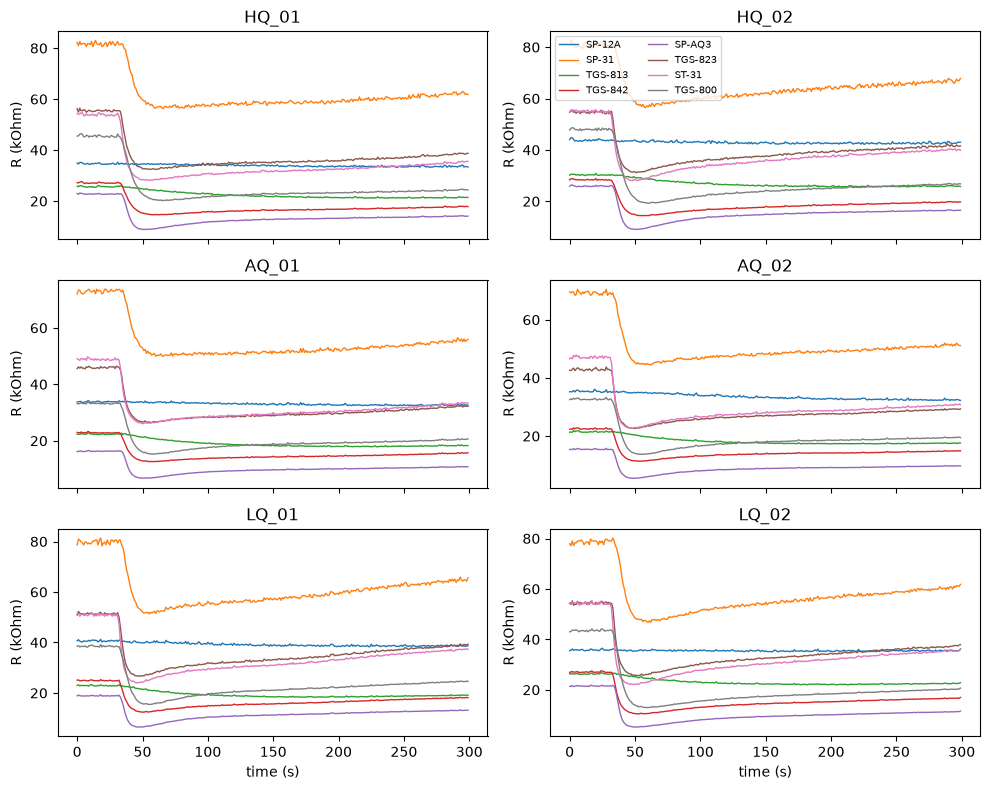

In [3]:
fig, axes = plt.subplots(3, 2, figsize=(10, 8), sharex=True)
for r, c in enumerate(S1_CLASSES):
    for k, i in enumerate(np.where(y == r)[0][:2]):
        ax = axes[r, k]
        for s in range(8): ax.plot(X[i, :, s], lw=1, label=S1_SENSORS[s])
        ax.set_title(f'{ids[i]}'); ax.set_ylabel('R (kOhm)')
axes[0, 1].legend(fontsize=7, ncol=2); axes[-1, 0].set_xlabel('time (s)'); axes[-1, 1].set_xlabel('time (s)')
plt.tight_layout(); plt.savefig(FIG / 'eda_s1_curves.png', dpi=130); plt.show()

**Signal structure.** Every curve is flat for about the first 30 s (the *baseline*, before the coffee headspace reaches the sensors), drops sharply, reaches a minimum after roughly 50–60 s for most sensors and then recovers slowly. This matches the measurement phase of the paper's cycle (its Figs. 5–6). We use the first 20 s as the baseline segment.

In [4]:
t_min = pd.DataFrame(X.argmin(1), columns=S1_SENSORS)
print('median time of minimum resistance (s):'); print(t_min.median().to_string())
base = pd.DataFrame(X[:, :20].mean(1), columns=S1_SENSORS).assign(cls=np.array(S1_CLASSES)[y])
print('\nmean pre-exposure baseline resistance per class (kOhm):')
base.groupby('cls').mean().loc[S1_CLASSES].round(1)

median time of minimum resistance (s):
SP-12A     245.0
SP-31       60.5
TGS-813    210.5
TGS-842     55.5
SP-AQ3      50.5
TGS-823     51.0
ST-31       49.0
TGS-800     60.0

mean pre-exposure baseline resistance per class (kOhm):


,SP-12A,SP-31,TGS-813,TGS-842,SP-AQ3,TGS-823,ST-31,TGS-800
cls,,,,,,,,
HQ,46.4,77.7,25.5,25.5,20.9,51.8,52.0,41.0
AQ,33.9,74.3,23.9,24.2,18.0,47.9,50.5,36.0
LQ,38.7,75.4,23.3,24.4,19.1,49.6,49.8,38.3


**An important observation.** The baseline resistance, measured *before* the coffee arrives, already differs by class (e.g. SP-12A, mean of the first 20 s: HQ 46.4, AQ 33.9, LQ 38.7 kΩ). Coffee aroma cannot cause that. It points to measurement sessions or sensor drift, i.e. the classes were probably recorded at different times. A classifier could exploit this instead of the aroma. Ablation AB3 measures how much accuracy depends on it by comparing representations that remove the baseline (R/R0, G/G0, z-score) with the raw ones.

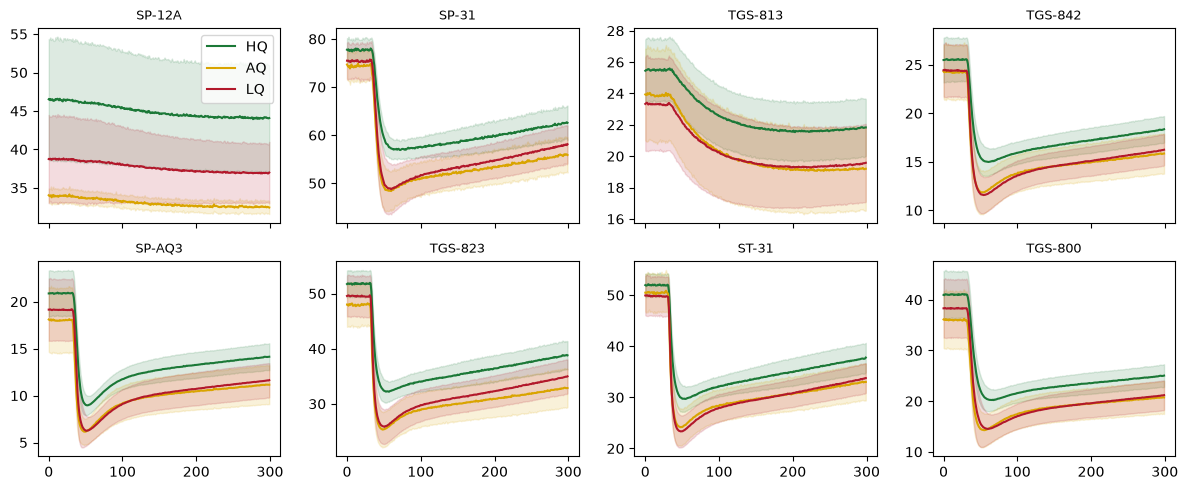

In [5]:
fig, axes = plt.subplots(2, 4, figsize=(12, 5), sharex=True)
colors = {'HQ': '#1b7837', 'AQ': '#d9a400', 'LQ': '#b2182b'}
for s, ax in enumerate(axes.ravel()):
    for r, c in enumerate(S1_CLASSES):
        m, sd = X[y == r, :, s].mean(0), X[y == r, :, s].std(0)
        ax.plot(m, color=colors[c], label=c); ax.fill_between(range(300), m - sd, m + sd, color=colors[c], alpha=0.15)
    ax.set_title(S1_SENSORS[s], fontsize=9)
axes[0, 0].legend(); plt.tight_layout(); plt.savefig(FIG / 'eda_s1_class_means.png', dpi=130); plt.show()

## The paper's view: static parameter + PCA
The paper's feature per sensor is the variation between maximum and minimum conductance (G = 1/R). We use ΔG = Gmax − Gmin, mean-centre the 58 × 8 matrix and project it on the first two principal components (the paper's Figs. 7 and 9). This PCA is purely descriptive (fitted on all data, no labels used).

explained variance PC1, PC2: [0.9851 0.0105] | PC1+PC2 = 0.9955


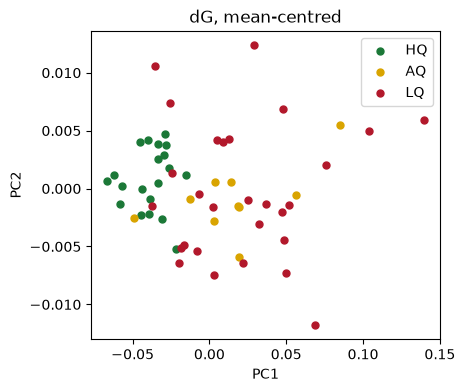

SP-12A     0.004
SP-31      0.047
TGS-813    0.027
TGS-842    0.345
SP-AQ3     0.852
TGS-823    0.113
ST-31      0.146
TGS-800    0.343
Name: PC1 loading, dtype: float64

In [6]:
from sklearn.decomposition import PCA
from src.features.enose import delta_g
F = delta_g(X, 'abs'); Z = F - F.mean(0); p = PCA().fit(Z); P = p.transform(Z)
print('explained variance PC1, PC2:', p.explained_variance_ratio_[:2].round(4), '| PC1+PC2 =', p.explained_variance_ratio_[:2].sum().round(4))
plt.figure(figsize=(4.5, 4))
for r, c in enumerate(S1_CLASSES): plt.scatter(P[y == r, 0], P[y == r, 1], label=c, color=colors[c], s=25)
plt.xlabel('PC1'); plt.ylabel('PC2'); plt.legend(); plt.title('dG, mean-centred'); plt.show()
pd.Series(p.components_[0], index=S1_SENSORS).round(3).rename('PC1 loading')

**Reading the PCA.** PC1+PC2 explain about 99.5 % of the variance, close to the paper's 99.62 %. But this number is mostly a consequence of mean-centring without scaling: the sensors with the largest ΔG dominate PC1 (SP-AQ3 has a loading of about 0.85; see the loadings). A high explained variance does not by itself mean the classes are separable.